<a href="https://colab.research.google.com/github/25f2008051/Project-1/blob/main/Machine%20learning_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preprocessing

### Access the dataset from here :

https://drive.google.com/file/d/1XztaPmhMMhBoEp7XuyDGS5Il_kLUlEEl/view?usp=sharing

### Notes:
* This exam consists of a **Regression** problem.
* The **target** feature is '**cltv**'.
* **Random state** should be taken as **42** wherever applicable.

# Metadata

1. **id**-Unique identifier of a customer
2. **gender**-Gender of the customer
3. **area**-Area of the customer
4. **qualification**-Highest Qualification of the customer
5. **income**-Income earned in a year (in rupees).
6. **marital_status**- 0:Single, 1: Married
7. **vintage**-No. of years since the first policy date.
8. **claim_amount**-Total Amount Claimed by the customer (in rupees)
9. **num_policies**-Total no. of policies issued by the customer
10. **policy**-Active policy of the customer
11. **type_of_policy**-Type of active policy
12. **cltv**- Customer life time value. It is the total amount of money a customer is expected to spend with your business, or on your products, during the lifetime of an average business relationship. **[TARGET]**

In [ ]:
# Load the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

DATA_URL = "https://drive.google.com/uc?id=1XztaPmhMMhBoEp7XuyDGS5Il_kLUlEEl&export=download"
df = pd.read_csv(DATA_URL)
df.head()

,id,gender,area,qualification,income,marital_status,vintage,claim_amount,num_policies,policy,type_of_policy,cltv
0,27529,Male,Urban,High School,42.99,0,0,3849.0,1,A,Platinum,66816
1,27116,Male,Rural,Bachelor,5.33,1,6,3006.0,More than 1,A,Gold,67164
2,6499,Female,Urban,High School,2.26,1,2,NaN,More than 1,A,Platinum,68076
3,61863,Male,Rural,High School,20.29,1,8,2844.0,More than 1,A,Platinum,63276
4,25045,Female,Urban,High School,5.63,0,6,6370.0,More than 1,A,Platinum,245844


### Q.2 [Marks: 2] How many records (rows) are there in the dataset? [MCQ]
Options

A) 6257

B) 6527

C) 5627

D) 6000

`Ans: 6257 (A)`

In [ ]:
# Solution
print(df.shape[0])

6257


### Q.3 [Marks: 2] What are the unique values of the feature `qualification` in the dataset? [MCQ]

A) ['High School', 'Bachelor']

B) ['High School', 'Bachelor', 'Masters', 'Others']

C) ['High School', 'Bachelor', 'Others']

D) ['Bachelor', 'Masters', 'Others']

`Ans: ['High School', 'Bachelor', 'Others'] (C)`

In [ ]:
# Solution
print(df['qualification'].unique())

['High School' 'Bachelor' 'Others']


### Q.4 [Marks: 3] Which of the following columns have numerical (int/float) data? [MSQ]

A) income

B) gender

C) vintage

D) policy

E) claim_amount

`Ans: income (A), vintage (C), claim_amount (E)`

In [ ]:
# Solution
print(df.dtypes)

id                  int64
gender             object
area               object
qualification      object
income            float64
marital_status      int64
vintage             int64
claim_amount      float64
num_policies       object
policy             object
type_of_policy     object
cltv                int64
dtype: object


### Q.5 [Marks: 4] Plot the `heatmap` of the correlation matrix of the numerical columns and mark the pair which has the **lowest (most negative)** correlation value. [MCQ]

A) marital_status & claim_amount

B) income & claim_amount

C) vintage & cltv

D) income & cltv

`Ans: marital_status & claim_amount (A)  [corr = -0.1341]`

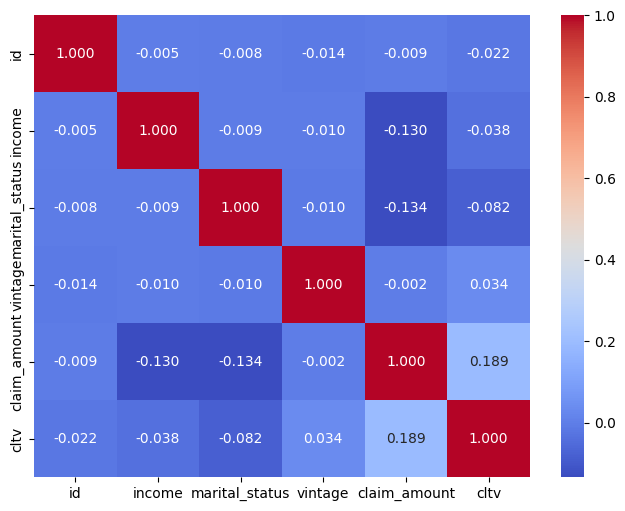

marital_status  claim_amount     -0.134100
claim_amount    marital_status   -0.134100
                income           -0.129808
income          claim_amount     -0.129808
dtype: float64


In [ ]:
# Solution
corr = df.select_dtypes(include='number').corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm')
plt.show()

# Locate the most negative off-diagonal pair
pairs = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print(pairs.sort_values().head(4))

### Q.6 [Marks: 2] Which of the following features has the **highest number** of `missing` values? [MCQ]

Options:

A) area

B) income

C) claim_amount

D) policy

`Ans: income (B)  [401 missing values]`

In [ ]:
# Solution
print(df.isna().sum().sort_values(ascending=False))

income            401
area              384
policy            372
claim_amount      360
qualification       0
gender              0
id                  0
marital_status      0
vintage             0
num_policies        0
type_of_policy      0
cltv                0
dtype: int64


### Q.7 [Marks: 4] Break the dataset into features(`X`) and label (`y`), where the column `cltv` goes to `y` and the rest of the columns go to `X`. Enter the **median** value of `cltv` column? [NAT]

`Ans: 66288.0`

In [ ]:
# Solution
X = df.drop(columns=['cltv'])
y = df['cltv']
print(y.median())

66288.0


### Q.8 [Marks : 3] Split the dataset into training and test dataset using `train_test_split` into `75:25` ratio while keeping random_state = 42. What is the shape of the test set (X_test)? [MCQ]

A) (1564, 11)

B) (1565, 11)

C) (1565, 12)

D) (4692, 11)

`Ans: (1565, 11) (B)`

In [ ]:
# Solution
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_test.shape)

(1565, 11)


### Q.9 [Marks: 2] Drop(remove) `id` column from train and test data because it is not useful in model training. Now how many of the remaining feature columns in the training dataset are of **object (string)** type? [NAT]

`Ans: 6  (gender, area, qualification, num_policies, policy, type_of_policy)`

In [ ]:
# Solution
X_train = X_train.drop(columns=['id'])
X_test = X_test.drop(columns=['id'])
obj_cols = X_train.select_dtypes(include='object').columns
print(list(obj_cols))
print(len(obj_cols))

['gender', 'area', 'qualification', 'num_policies', 'policy', 'type_of_policy']
6


### Q.10 [Marks: 2] Compute and write the **mean** of the `income` column of X_train while ignoring the missing values. Replace all NaN values in the income column of X_train and X_test by the mean computed from the X_train (upto two decimal). [NAT]

`Ans: 13.73`

In [ ]:
# Solution
income_mean = X_train['income'].mean()
print(round(income_mean, 2))
X_train['income'] = X_train['income'].fillna(income_mean)
X_test['income'] = X_test['income'].fillna(income_mean)

13.73


### Q.11 [Marks: 2] How many missing values are present in the `policy` column of **X_test**? After answering, replace all NaN values in the `policy` column of X_train and X_test by the most frequent value in X_train. [NAT]

`Ans: 102`

In [ ]:
# Solution
print(X_test['policy'].isna().sum())
policy_mode = X_train['policy'].mode()[0]
print('Most frequent policy in X_train:', policy_mode)
X_train['policy'] = X_train['policy'].fillna(policy_mode)
X_test['policy'] = X_test['policy'].fillna(policy_mode)

102
Most frequent policy in X_train: A


### Q.12 [Marks: 2] Replace all NaN values in the `area` column of X_train and X_test by the most frequent value from X_train. After replacing, how many records in **X_train** have `area` equal to that most frequent value? [NAT]

`Ans: 3407  (most frequent value = 'Urban')`

In [ ]:
# Solution
area_mode = X_train['area'].mode()[0]
print('Most frequent area in X_train:', area_mode)
X_train['area'] = X_train['area'].fillna(area_mode)
X_test['area'] = X_test['area'].fillna(area_mode)
print((X_train['area'] == area_mode).sum())

Most frequent area in X_train: Urban
3407


### Q.13 [Marks: 2] Replace all NaN values in the claim_amount column of X_train and X_test by the **median** of claim_amount computed from X_train. After replacing, what is the **mean** of the claim_amount column in **X_test**? (correct upto two decimal places) [NAT]

`Ans: 4260.88`

In [ ]:
# Solution
claim_median = X_train['claim_amount'].median()
X_train['claim_amount'] = X_train['claim_amount'].fillna(claim_median)
X_test['claim_amount'] = X_test['claim_amount'].fillna(claim_median)
print(round(X_test['claim_amount'].mean(), 2))

4260.88


### Q.14 [Marks: 4] Apply `StandardScaler` on the `vintage` column of X_train (store the result in a separate variable, do **not** overwrite X_train). Compute and write the **maximum** value of the scaled `vintage` column. (correct upto 2 decimal) [NAT]

`Ans: 1.47`

In [ ]:
# Solution
from sklearn.preprocessing import StandardScaler
vintage_scaled = StandardScaler().fit_transform(X_train[['vintage']])
print(round(vintage_scaled.max(), 2))

1.47


## Apply preprocessing on features of X_train and X_test dataset.

### For Categorical Features

* Apply OneHotEncoding from `sklearn` library on all categorical features. Do Encoding in the order of following list

  `Categorical Features = ['gender', 'area','qualification','marital_status', 'num_policies', 'policy', 'type_of_policy']`

Lets call the transformed categorical feature matrix $X1$

### For Numerical Features

- apply **StandardScaler** and transform the dataset. Do scaling in the order of following list:

  `Numerical Features =  [ 'income', 'vintage', 'claim_amount' ]`

  - Lets call the transformed numerical feature matrix $X2$

### **Concatenate**(One Hot Encoded Features, Scaled Numerical Features)

After combining transformed categorical feature($X_1$) matrix and transformed numerical feature matrix ($X_2$) (side by side in that order), the output will be $X=[X_1 X_2]$

### Hints
* Apply ColumnTransformer to encode categorical columns and scaling on numerical columns with required preprocessor

* Another way is to separately encode all categorical columns and scale numerical columns and do concatenate (`h-stack`) both. keep categorical columns in front of numerical while concatenating.

* The transformed (as described by above steps) X_train and X_test, should be considered as X_train and X_test henceforth.

In [ ]:
# Solution
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['gender', 'area', 'qualification', 'marital_status', 'num_policies', 'policy', 'type_of_policy']
num_cols = ['income', 'vintage', 'claim_amount']

ct = ColumnTransformer([
    ('ohe', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cat_cols),
    ('scale', StandardScaler(), num_cols)
])
X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)
print(X_train.shape, X_test.shape)

(4692, 20) (1565, 20)


## Q.15 [Marks: 10] How many columns are produced by the **One-Hot Encoding step alone** (i.e. the number of columns in $X_1$)? [MCQ]

[Options]

A) 7

B) 14

C) 17

D) 20

`Ans: 17 (C)`

In [ ]:
# Solution
print(ct.named_transformers_['ohe'].get_feature_names_out().shape[0])

17


# Model Building

### Q.16 [Marks: 5] Apply `SequentialFeatureSelector` transformer with direction= 'forward' with `LinearRegression()` estimator and select **6** features by fitting to the X_train and y_train.

  `Use cv = KFold(n_splits=5,random_state=42,shuffle=True) in SequentialFeatureSelector.`

### Which of the following options represents the correct integer index of the selected features list? [MCQ]

A) [ 4  5  7  9 13 19]

B) [ 3  6  9 12 13 19]

C) [ 4  6  7  9 14 19]

D) [ 1  5  7  9 13 18]

E) [ 4  5  8 10 13 19]

`Ans: [ 4  5  7  9 13 19] (A)`

In [ ]:
# Solution
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold

cv = KFold(n_splits=5, random_state=42, shuffle=True)
sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select=6, direction='forward', cv=cv)
sfs.fit(X_train, y_train)
print(np.where(sfs.get_support())[0])

[ 4  5  7  9 13 19]


### Q.17 [Marks: 3] Apply `LinearRegression` on the training set(`X_train` and `y_train`). What is the **mean absolute error** on the test set(`X_test` and `y_test`)? (Upto 2 digits after decimal point) [NAT]

`Ans: 52712.56`

In [ ]:
# Solution
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
lr = LinearRegression().fit(X_train, y_train)
print(round(mean_absolute_error(y_test, lr.predict(X_test)), 2))

52712.56


### Q.18 [Marks: 6] Using the `LinearRegression` model, compute the `cross-validation scores` for `5 splits` on training data (X_train and y_train) using `cross_val_score`. Enter the **mean** value of the $R^2$ scores obtained. (Upto 4 digits after decimal point) [NAT]

`Use cv = KFold(n_splits=5,random_state=42,shuffle=True) in cross_val_score.`

(**Hint**: By default cross_val_score uses LinearRegression's scoring metric, which is $R^2$ score.)

`Ans: 0.1470 (Range: 0.1450-0.1490)`

In [ ]:
# Solution
from sklearn.model_selection import cross_val_score
scores = cross_val_score(LinearRegression(), X_train, y_train, cv=KFold(n_splits=5, random_state=42, shuffle=True))
print(scores)
print(round(scores.mean(), 4))

[0.15765982 0.14449678 0.14566491 0.13373985 0.15322638]
0.147


### Q.19 [Marks: 5] Apply `Ridge` regression with **random_state=42** and **alpha=10** on training set(`X_train and y_train`) and calculate the $R^2$ score on test_set (`X_test and y_test`). What is the correct score (Upto 4 digits after decimal point)? [NAT]

`Ans: 0.1421`

In [ ]:
# Solution
from sklearn.linear_model import Ridge
ridge = Ridge(alpha=10, random_state=42).fit(X_train, y_train)
print(round(ridge.score(X_test, y_test), 4))

0.1421


### Q.20: [Marks: 6] Apply `Lasso` regression with **random_state=42** and **regularization rate (alpha)=100** on the training data(`X_train & y_train`). Enter the value of the **intercept** correct upto 2 digits after decimal point. [NAT]

`Ans: 116658.43`

In [ ]:
# Solution
from sklearn.linear_model import Lasso
lasso = Lasso(alpha=100, random_state=42).fit(X_train, y_train)
print(round(lasso.intercept_, 2))

116658.43


### Q.21 [Marks: 5] Fit SGDRegressor(`random_state=42`) estimator on the training data(`X_train & y_train`) and predict labels for test_data(`X_test`), lets call it as y_test_predict. The parameters are initialized with default values. Calculate the **root mean squared error** between y_test and y_test_predict. (Correct upto two decimals) [NAT]

`Ans: 88459.51`

In [ ]:
# Solution
from sklearn.linear_model import SGDRegressor
sgd = SGDRegressor(random_state=42).fit(X_train, y_train)
y_test_predict = sgd.predict(X_test)
print(round(np.sqrt(mean_squared_error(y_test, y_test_predict)), 2))

88459.51


### Q.22: [Marks: 6] Using SGDRegressor(random_state=42) as an estimator for exactly **25** iterations (`max_iter=25`). Write the correct $R^2$ score on test data [NAT] (correct Upto 4 digits)

`Ans: 0.1397`

In [ ]:
# Solution
sgd25 = SGDRegressor(random_state=42, max_iter=25).fit(X_train, y_train)
print(round(sgd25.score(X_test, y_test), 4))

0.1397


# (Common Instructions for Question 23 and 24)

### Create a pipeline Using PolynomialFeatures as transformer and Lasso as estimator. Use GridSearchCV with this created pipeline and following hyperparameter values on training data(X_train, y_train) to fit the model .
```
1. Keep polynomial degree as : [1, 2]
2. alpha value to be taken as : np.logspace(-2, 1, num=4)
3. scoring : neg_mean_squared_error
```
(**Note**: Kindly ignore the warning.)

In [ ]:
# Solution
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([('poly', PolynomialFeatures()), ('lasso', Lasso())])
params = {'poly__degree': [1, 2], 'lasso__alpha': np.logspace(-2, 1, num=4)}
grid = GridSearchCV(pipe, params, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(X_train, y_train)
print(grid.best_params_)

{'lasso__alpha': np.float64(10.0), 'poly__degree': 2}


### Q.23 [Marks: 6] Mark the best `alpha` value you got using above instructions. [MCQ]

A) 0.01

B) 0.1

C) 1.0

D) 10.0

`Ans: 10.0 (D)`

In [ ]:
# Solution
print(grid.best_params_['lasso__alpha'])

10.0


### Q.24 [Marks: 6] Enter the best polynomial degree value you got using above instructions. [NAT]

`Ans: 2`

In [ ]:
# Solution
print(grid.best_params_['poly__degree'])

2


# (Common Instructions for Question 25 and 26)
### To Reduce number of dimensions of training data with PCA. Fit the PCA model using following parameter values on training data.
```
n_components=7
svd_solver='full'
whiten=True
random_state=42
```

In [ ]:
# Solution
from sklearn.decomposition import PCA
pca = PCA(n_components=7, svd_solver='full', whiten=True, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

### Q.25 [Marks: 5] What is the sum of `explained_variance_ratio_` ? (upto 4 decimal) [NAT]

`Ans: 0.7816`

In [ ]:
# Solution
print(round(pca.explained_variance_ratio_.sum(), 4))

0.7816


### Q.26 [Marks: 6] Use PCA transformed training data from earlier question and y_train to fit the `RidgeCV` estimator model having `alpha values as [0.01, 0.1, 1, 10, 100]`. Calculate the $R^2$ score you got from the model for transformed test data(PCA transformed X_test). [NAT] (upto 4 decimal)

`Ans: 0.1308`

In [ ]:
# Solution
from sklearn.linear_model import RidgeCV
rcv = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]).fit(X_train_pca, y_train)
print(round(rcv.score(X_test_pca, y_test), 4))

0.1308
